# Risk-Parity Swiss Equity

Liquid Swiss equity universe with trailing covariance shrinkage and approximately equal risk-contribution portfolio weights.

## 1. Imports and Paths

In [1]:

import os
import sys
from pathlib import Path

os.environ.setdefault('MPLCONFIGDIR', '/tmp/matplotlib')

import numpy as np
import pandas as pd
import matplotlib
if 'ipykernel' not in sys.modules:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.optimize import minimize


def find_repo_root(start=None):
    """Walk up from the notebook folder to the repository root."""
    start = Path.cwd() if start is None else Path(start)
    for candidate in [start, *start.parents]:
        if (candidate / 'framework').is_dir():
            return candidate
    raise FileNotFoundError('Could not locate the repository root (folder containing framework/).')


REPO_ROOT = find_repo_root()
DATA_PATH = REPO_ROOT / 'data'
for module_dir in ('framework', 'signals', 'data_utils'):
    if str(REPO_ROOT / module_dir) not in sys.path:
        sys.path.insert(0, str(REPO_ROOT / module_dir))
missing = [f for f in ['market_data.parquet', 'jkp_data.parquet', 'spi_index.csv'] if not (DATA_PATH / f).exists()]
if missing:
    raise FileNotFoundError(f'Missing in {DATA_PATH}: {missing}. See data/README.md.')

print('REPO_ROOT:', REPO_ROOT)
print('DATA_PATH:', DATA_PATH)


REPO_ROOT: <repo>
DATA_PATH: <repo>/data


In [2]:

from helper_functions import load_data_spi, align_market_data_with_jkp_data
from estimation.covariance import make_pos_def
from optimization.optimization import Optimization, Objective
from backtesting.backtest import Backtest
from backtesting.backtest_data import BacktestData
from backtesting.backtest_service import BacktestService
from backtesting.selection import Selection
from backtesting.backtest_item_builder.bib_classes import (
    SelectionItemBuilder,
    OptimizationItemBuilder,
)
from backtesting.backtest_item_builder.bibfn_selection import (
    bibfn_selection_gaps,
    bibfn_selection_min_volume,
)
from backtesting.backtest_item_builder.bibfn_optimization_data import (
    bibfn_return_series,
)
from backtesting.backtest_item_builder.bibfn_constraints import (
    bibfn_budget_constraint,
    bibfn_box_constraints,
)


## 2. Data

In [3]:

market_data = pd.read_parquet(DATA_PATH / 'market_data.parquet')
jkp_data = pd.read_parquet(DATA_PATH / 'jkp_data.parquet')
spi = load_data_spi(path=str(DATA_PATH) + os.sep)

market_data_ffill, jkp_data = align_market_data_with_jkp_data(
    market_data=market_data,
    jkp_data=jkp_data,
)

data = BacktestData()
data.market_data = market_data_ffill
data.jkp_data = jkp_data
data.bm_series = spi

print('market_data:', data.market_data.shape)
print('jkp_data:', data.jkp_data.shape)
print('SPI:', data.bm_series.index.min().date(), 'to', data.bm_series.index.max().date())
print('Sector non-null share:', data.market_data['sector'].notna().mean().round(4))


market_data: (1408989, 4)
jkp_data: (83421, 153)
SPI: 1999-01-02 to 2024-04-30
Sector non-null share: 0.0016


## 3. Parameters

Risk parity is sensitive to noisy covariance estimates, so the covariance matrix is shrunk toward its diagonal. The stock cap keeps low-volatility names from dominating capital weights.

In [4]:

N_MONTHS = 3
START_DATE = '2003-01-01'

FIXED_COSTS = 0.01
VARIABLE_COSTS = 0.002

RETURN_HISTORY_DAYS = 252 * 2
MIN_RETURN_OBS = 400
GAP_LOOKBACK_DAYS = 365
MAX_ZERO_VOLUME_GAP_DAYS = 21
LIQUIDITY_LOOKBACK_DAYS = 365
MIN_MEDIAN_LIQUIDITY = 500_000
COVARIANCE_LOOKBACK_DAYS = 252 * 3
COVARIANCE_SHRINKAGE = 0.50

MAX_STOCK_WEIGHT = 0.10
ERC_MAX_ITER = 1000
ERC_FTOL = 1e-10
RISK_CONTRIBUTION_TOL = 1e-8

print('Covariance lookback days:', COVARIANCE_LOOKBACK_DAYS)
print('Covariance shrinkage to sample covariance:', COVARIANCE_SHRINKAGE)
print('Max stock weight:', MAX_STOCK_WEIGHT)


Covariance lookback days: 756
Covariance shrinkage to sample covariance: 0.5
Max stock weight: 0.1


## 4. Builder Functions

The selection builders use the framework's `SelectionItemBuilder` interface. The optimizer is notebook-local but still inherits from `Optimization` and reads the constraints prepared by `OptimizationItemBuilder`.

In [5]:

def current_selected_ids(bs, fallback_index):
    selected = bs.selection.selected
    if selected is None or len(selected) == 0:
        return list(pd.Index(fallback_index).astype(str))
    return list(pd.Index(selected).astype(str))


def bibfn_selection_return_history(bs, rebdate, **kwargs):
    width = kwargs.get('width', RETURN_HISTORY_DAYS)
    min_obs = kwargs.get('min_obs', MIN_RETURN_OBS)

    ret = bs.data.get_return_series(
        end_date=rebdate,
        width=width,
        weekdays_only=True,
        fillna_value=None,
    )
    ids = current_selected_ids(bs, ret.columns)
    ret = ret.reindex(columns=ids)
    valid_obs = ret.notna().sum(axis=0)

    return pd.DataFrame({
        'values': valid_obs,
        'binary': (valid_obs >= min_obs).astype(int),
    })


def shrink_covariance(return_series, shrinkage=COVARIANCE_SHRINKAGE):
    sample = return_series.cov().fillna(0)
    diag = pd.DataFrame(
        np.diag(np.diag(sample)),
        index=sample.index,
        columns=sample.columns,
    )
    cov = shrinkage * sample + (1 - shrinkage) * diag
    cov = (cov + cov.T) / 2
    try:
        cov_pd = pd.DataFrame(
            make_pos_def(cov.to_numpy()),
            index=cov.index,
            columns=cov.columns,
        )
    except Exception:
        cov_pd = cov + np.eye(cov.shape[0]) * 1e-8
    return cov_pd


def cap_and_redistribute(weights, cap):
    weights = weights.copy().astype(float)
    weights = weights[weights > 0]
    if weights.empty:
        return weights
    if len(weights) * cap < 1:
        return weights / weights.sum()

    free = pd.Index(weights.index)
    capped = pd.Series(0.0, index=weights.index)
    remaining = 1.0

    while len(free) > 0:
        scaled = weights.loc[free] / weights.loc[free].sum() * remaining
        over = scaled > cap
        if not over.any():
            capped.loc[free] = scaled
            break
        capped.loc[scaled[over].index] = cap
        remaining = 1.0 - capped.sum()
        free = scaled[~over].index

    return capped / capped.sum()


def inverse_volatility_weights(return_series, max_weight=MAX_STOCK_WEIGHT):
    vol = return_series.std(axis=0) * np.sqrt(252)
    inv_vol = 1 / vol.replace(0, np.nan)
    inv_vol = inv_vol.replace([np.inf, -np.inf], np.nan).dropna()
    if inv_vol.empty:
        return pd.Series(1 / return_series.shape[1], index=return_series.columns)
    weights = inv_vol / inv_vol.sum()
    return cap_and_redistribute(weights, max_weight)


def risk_contribution_fraction(weights, cov):
    weights = pd.Series(weights, index=cov.index).astype(float)
    marginal = cov @ weights
    port_var = float(weights @ marginal)
    if port_var <= 0 or not np.isfinite(port_var):
        return pd.Series(np.nan, index=cov.index)
    return weights * marginal / port_var


class EqualRiskContributionPortfolio(Optimization):
    def __init__(
        self,
        covariance_shrinkage=COVARIANCE_SHRINKAGE,
        max_iter=ERC_MAX_ITER,
        ftol=ERC_FTOL,
        **kwargs,
    ):
        super().__init__(
            covariance_shrinkage=covariance_shrinkage,
            max_iter=max_iter,
            ftol=ftol,
            solver_name='scipy-slsqp',
            **kwargs,
        )

    def set_objective(self, optimization_data):
        ret = optimization_data['return_series'].dropna(axis=1, how='all').fillna(0)
        cov = shrink_covariance(
            ret,
            shrinkage=self.params['covariance_shrinkage'],
        )
        self.objective = Objective(return_series=ret, cov=cov)
        return None

    def solve(self):
        ret = self.objective.coefficients['return_series']
        cov = self.objective.coefficients['cov']
        ids = list(cov.index)
        n = len(ids)

        if n == 0:
            self.results.update({'weights': {}, 'status': False, 'message': 'empty universe'})
            return None

        lower = pd.Series(0.0, index=ids)
        upper = pd.Series(MAX_STOCK_WEIGHT, index=ids)
        box = self.constraints.box
        if box.get('box_type') != 'NA' and box.get('lower') is not None:
            lower = pd.Series(box['lower']).reindex(ids).fillna(0.0).astype(float)
        if box.get('box_type') != 'NA' and box.get('upper') is not None:
            upper = pd.Series(box['upper']).reindex(ids).fillna(MAX_STOCK_WEIGHT).astype(float)

        if upper.sum() < 1 - 1e-8:
            upper = upper / upper.sum()

        x0 = inverse_volatility_weights(ret, max_weight=float(upper.max())).reindex(ids).fillna(0.0)
        x0 = np.maximum(x0.to_numpy(dtype=float), lower.to_numpy(dtype=float))
        x0 = np.minimum(x0, upper.to_numpy(dtype=float))
        x0 = x0 / x0.sum() if x0.sum() > 0 else np.repeat(1 / n, n)

        cov_np = cov.to_numpy(dtype=float)
        target = np.repeat(1 / n, n)

        def objective(w):
            marginal = cov_np @ w
            port_var = float(w @ marginal)
            if port_var <= 0 or not np.isfinite(port_var):
                return 1e6
            rc = w * marginal / port_var
            return float(((rc - target) ** 2).sum())

        constraints = [{'type': 'eq', 'fun': lambda w: np.sum(w) - 1.0}]
        bounds = list(zip(lower.to_numpy(dtype=float), upper.to_numpy(dtype=float)))

        result = minimize(
            objective,
            x0=x0,
            method='SLSQP',
            bounds=bounds,
            constraints=constraints,
            options={'maxiter': int(self.params['max_iter']), 'ftol': float(self.params['ftol']), 'disp': False},
        )

        if result.success and np.isfinite(result.fun):
            weights = pd.Series(result.x, index=ids).clip(lower=0)
            weights = weights / weights.sum()
            status = True
            message = result.message
        else:
            weights = inverse_volatility_weights(ret, max_weight=float(upper.max())).reindex(ids).fillna(0.0)
            weights = weights / weights.sum()
            status = False
            message = result.message if hasattr(result, 'message') else 'SLSQP failed, inverse-vol fallback used'

        rc = risk_contribution_fraction(weights, cov)
        self.results.update({
            'weights': weights.to_dict(),
            'status': status,
            'message': str(message),
            'risk_contribution_error': float(((rc - 1 / len(rc)) ** 2).sum()),
        })
        return None


class FreshSelectionBacktestService(BacktestService):
    def build_selection(self, rebdate):
        self.selection = Selection()
        return super().build_selection(rebdate)


## 5. Rebalancing Dates

In [6]:

jkp_dates = data.jkp_data.index.get_level_values('date').unique().sort_values()
market_min_date = data.market_data.index.get_level_values('date').min()
market_max_date = data.market_data.index.get_level_values('date').max()

rebdates = (
    jkp_dates[(jkp_dates > market_min_date) & (jkp_dates <= market_max_date)][::N_MONTHS]
    .strftime('%Y-%m-%d')
    .tolist()
)
rebdates = [date for date in rebdates if date > START_DATE]

print('Number of rebalancing dates:', len(rebdates))
print('First rebalance:', rebdates[0])
print('Last rebalance:', rebdates[-1])


Number of rebalancing dates: 85
First rebalance: 2003-01-31
Last rebalance: 2024-01-31


## 6. Backtest

In [7]:

selection_item_builders = {
    'return_history': SelectionItemBuilder(
        bibfn=bibfn_selection_return_history,
        width=RETURN_HISTORY_DAYS,
        min_obs=MIN_RETURN_OBS,
    ),
    'gaps': SelectionItemBuilder(
        bibfn=bibfn_selection_gaps,
        width=GAP_LOOKBACK_DAYS,
        n_days=MAX_ZERO_VOLUME_GAP_DAYS,
    ),
    'min_volume': SelectionItemBuilder(
        bibfn=bibfn_selection_min_volume,
        width=LIQUIDITY_LOOKBACK_DAYS,
        min_volume=MIN_MEDIAN_LIQUIDITY,
        agg_fn=np.median,
    ),
}

optimization_item_builders = {
    'return_series': OptimizationItemBuilder(
        bibfn=bibfn_return_series,
        width=COVARIANCE_LOOKBACK_DAYS,
        weekdays_only=True,
        fillna_value=0,
    ),
    'budget': OptimizationItemBuilder(
        bibfn=bibfn_budget_constraint,
        budget=1,
    ),
    'box': OptimizationItemBuilder(
        bibfn=bibfn_box_constraints,
        box_type='LongOnly',
        lower=0,
        upper=MAX_STOCK_WEIGHT,
    ),
}

optimization = EqualRiskContributionPortfolio(
    covariance_shrinkage=COVARIANCE_SHRINKAGE,
    max_iter=ERC_MAX_ITER,
    ftol=ERC_FTOL,
)

bs_s23 = FreshSelectionBacktestService(
    data=data,
    selection_item_builders=selection_item_builders,
    optimization_item_builders=optimization_item_builders,
    optimization=optimization,
    rebdates=rebdates,
    quiet=True,
)

bt_s23 = Backtest()
bt_s23.run(bs=bs_s23)

weights_s23 = bt_s23.strategy.get_weights_df()
print('Backtest completed.')
print('Weight matrix:', weights_s23.shape)
print('Average holdings:', weights_s23.gt(0).sum(axis=1).mean().round(1))
print('Average max stock weight:', weights_s23.max(axis=1).mean().round(3))


Backtest completed.
Weight matrix: (85, 177)
Average holdings: 89.0
Average max stock weight: 0.066


In [8]:
# Notebook-local simulator because the framework's Strategy.simulate cost branch uses
# integer labels that are positional in older pandas but labels in pandas 3.
def simulate_strategy_returns(strategy, return_series, fc=0.0, vc=0.0, n_days_per_year=252):
    gross_returns = strategy.simulate(return_series=return_series, fc=0.0, vc=0.0)
    net_returns = gross_returns.copy()

    if vc != 0 and len(net_returns) > 0:
        turnover = strategy.turnover(return_series=return_series, rescale=False)
        turnover.index = pd.to_datetime(turnover.index)
        variable_costs = turnover * vc
        if len(variable_costs) > 0:
            net_returns.iloc[0] -= variable_costs.iloc[0]
            common_dates = net_returns.index.intersection(variable_costs.iloc[1:].index)
            net_returns.loc[common_dates] -= variable_costs.loc[common_dates]

    if fc != 0 and len(net_returns) > 1:
        elapsed_days = (net_returns.index[1:] - net_returns.index[:-1]).to_numpy()
        elapsed_days = elapsed_days.astype('timedelta64[D]').astype(int)
        fixed_costs = (1 + fc) ** (elapsed_days / n_days_per_year) - 1
        net_returns.iloc[1:] -= fixed_costs

    return net_returns

## 7. Returns

In [9]:

return_series = data.get_return_series(weekdays_only=False)

s23_gross_returns = simulate_strategy_returns(
    bt_s23.strategy,
    return_series=return_series,
    fc=0,
    vc=0,
)
s23_gross_returns.name = 'Strategy gross'

s23_net_returns = simulate_strategy_returns(
    bt_s23.strategy,
    return_series=return_series,
    fc=FIXED_COSTS,
    vc=VARIABLE_COSTS,
)
s23_net_returns.name = 'Strategy net'

comparison = pd.concat(
    {
        'Strategy net': s23_net_returns,
        'Strategy gross': s23_gross_returns,
        'SPI': data.bm_series,
    },
    axis=1,
    sort=False,
).dropna()

print(comparison.index.min().date(), 'to', comparison.index.max().date())
print(comparison.describe().T)


2003-02-03 to 2024-04-30
            count      mean       std       min       25%       50%       75%  \
Strategy net    5609.0  0.000268  0.007858 -0.083742 -0.003036  0.000364  0.004176   
Strategy gross  5609.0  0.000329  0.007858 -0.083702 -0.002990  0.000440  0.004248   
SPI        5609.0  0.000332  0.009932 -0.091109 -0.004052  0.000350  0.005263   

                max  
Strategy net    0.063242  
Strategy gross  0.063282  
SPI        0.105788  


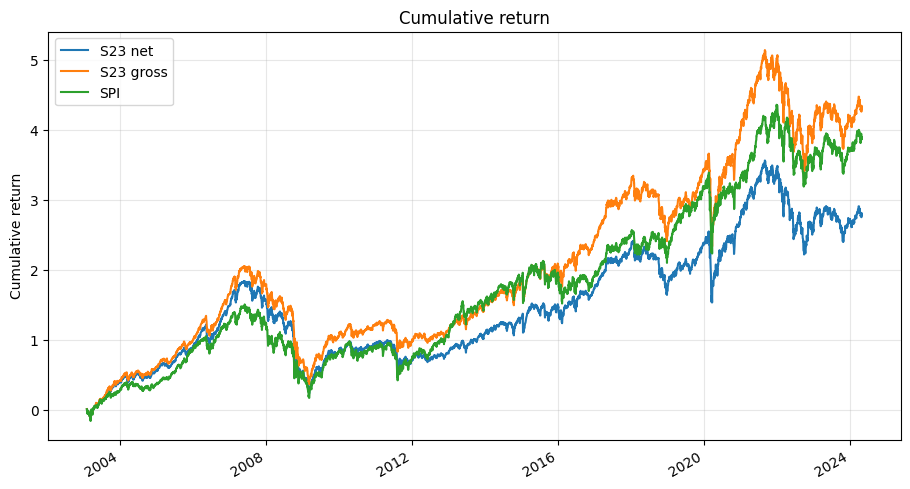

In [10]:

ax = ((1 + comparison).cumprod() - 1).plot(figsize=(11, 6), title='Cumulative return')
ax.set_ylabel('Cumulative return')
ax.grid(alpha=0.3)
plt.show()


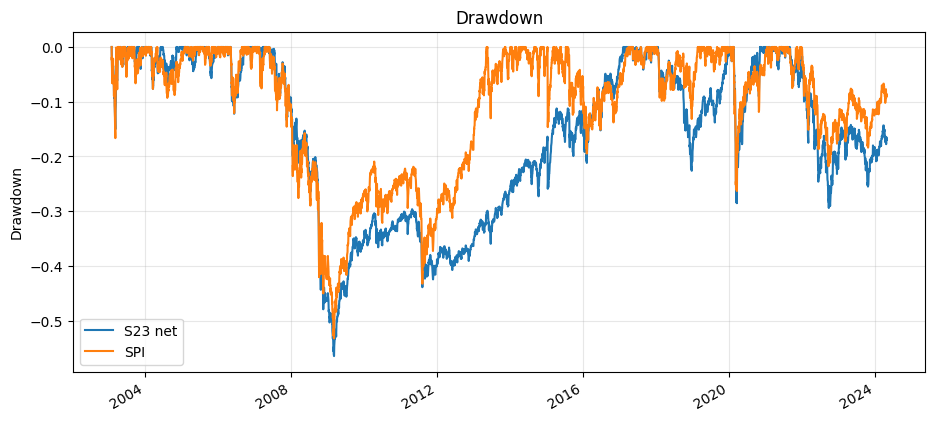

In [11]:

def drawdown(return_df):
    wealth = (1 + return_df).cumprod()
    return wealth / wealth.cummax() - 1


ax = drawdown(comparison[['Strategy net', 'SPI']]).plot(figsize=(11, 5), title='Drawdown')
ax.set_ylabel('Drawdown')
ax.grid(alpha=0.3)
plt.show()


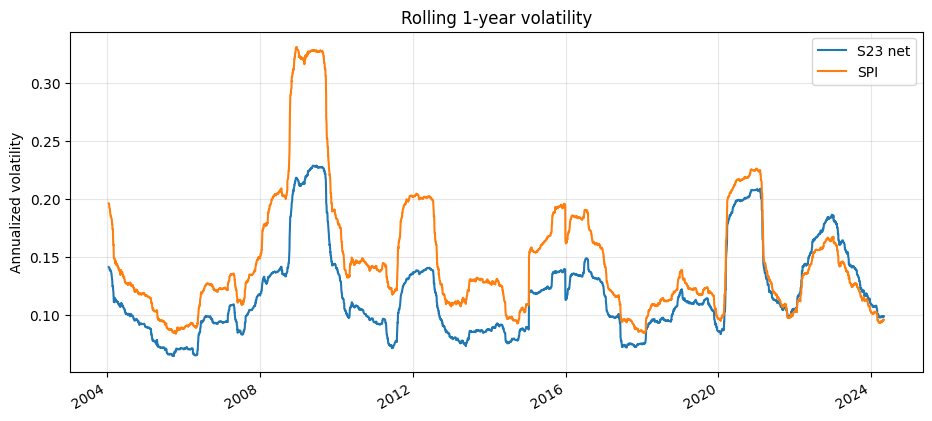

In [12]:

rolling_1y_vol = comparison.rolling(252).std() * np.sqrt(252)
ax = rolling_1y_vol[['Strategy net', 'SPI']].plot(figsize=(11, 5), title='Rolling 1-year volatility')
ax.set_ylabel('Annualized volatility')
ax.grid(alpha=0.3)
plt.show()


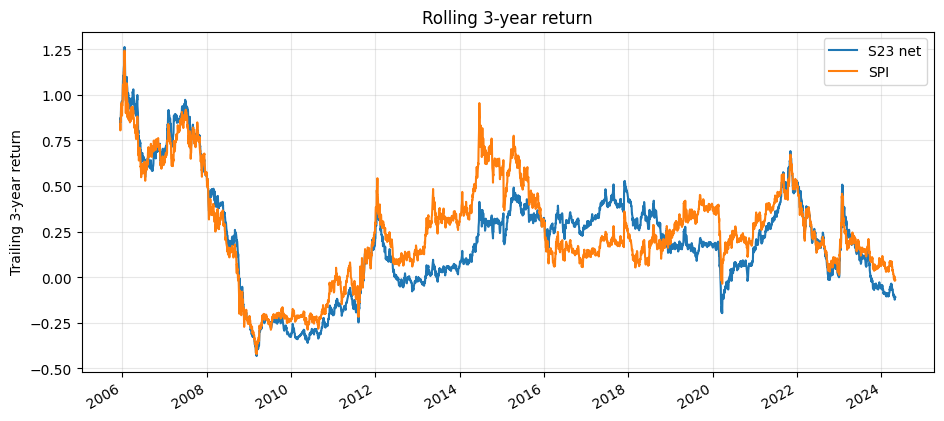

In [13]:

rolling_3y_return = (1 + comparison).rolling(252 * 3).apply(np.prod, raw=True) - 1
ax = rolling_3y_return[['Strategy net', 'SPI']].plot(figsize=(11, 5), title='Rolling 3-year return')
ax.set_ylabel('Trailing 3-year return')
ax.grid(alpha=0.3)
plt.show()


## 8. Statistics

In [14]:

def annualized_return(r, periods_per_year=252):
    r = r.dropna()
    if len(r) == 0:
        return np.nan
    return (1 + r).prod() ** (periods_per_year / len(r)) - 1


def annualized_volatility(r, periods_per_year=252):
    return r.dropna().std() * np.sqrt(periods_per_year)


def max_drawdown(r):
    dd = drawdown(r.to_frame()).iloc[:, 0]
    return dd.min()


def performance_stats(return_df, periods_per_year=252):
    rows = {}
    for col in return_df.columns:
        r = return_df[col].dropna()
        ann_ret = annualized_return(r, periods_per_year)
        ann_vol = annualized_volatility(r, periods_per_year)
        rows[col] = {
            'annualized_return': ann_ret,
            'annualized_volatility': ann_vol,
            'sharpe_rf0': ann_ret / ann_vol if ann_vol != 0 else np.nan,
            'max_drawdown': max_drawdown(r),
            'daily_mean': r.mean(),
            'daily_std': r.std(),
        }
    return pd.DataFrame(rows).T


full_stats = performance_stats(comparison)
last_5y_stats = performance_stats(comparison.loc[comparison.index >= comparison.index.max() - pd.DateOffset(years=5)])

stats = pd.concat({'Full sample': full_stats, 'Last 5 years': last_5y_stats}, axis=0)
stats_display = stats.copy()
stats_display['sharpe_rf0'] = stats_display['sharpe_rf0'].round(2)

formatters = {
    'annualized_return': '{:.2%}',
    'annualized_volatility': '{:.2%}',
    'sharpe_rf0': '{:.2f}',
    'max_drawdown': '{:.2%}',
    'daily_mean': '{:.4%}',
    'daily_std': '{:.4%}',
}
stats_display.style.format(formatters)


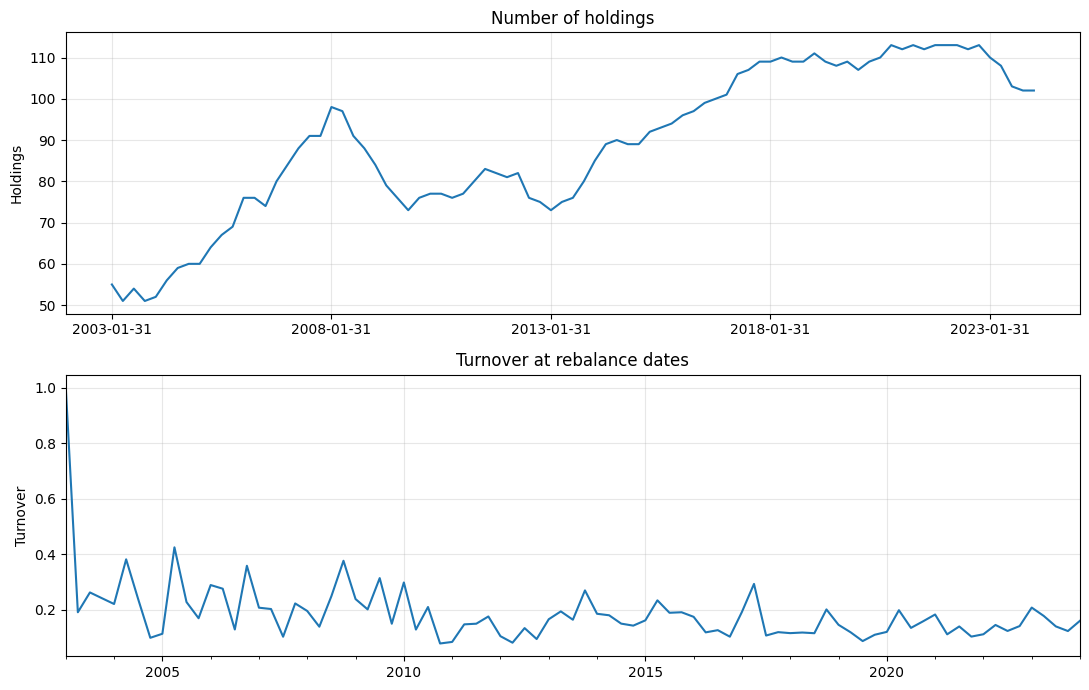

Average turnover: 0.187
Median turnover: 0.163


In [15]:

turnover_s23 = bt_s23.strategy.turnover(return_series=return_series, rescale=False)
turnover_s23.index = pd.to_datetime(turnover_s23.index)
turnover_s23.name = 'turnover'

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=False)
weights_s23.gt(0).sum(axis=1).plot(ax=axes[0], title='Number of holdings')
axes[0].set_ylabel('Holdings')
axes[0].grid(alpha=0.3)
turnover_s23.plot(ax=axes[1], title='Turnover at rebalance dates')
axes[1].set_ylabel('Turnover')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

print('Average turnover:', turnover_s23.mean().round(3))
print('Median turnover:', turnover_s23.median().round(3))


## 9. Risk-Contribution Diagnostics

This verifies whether the optimizer is actually equalizing risk contributions instead of simply producing inverse-volatility weights.

In [16]:

def compute_risk_contribution_diagnostics(weights_df, data, lookback_days=COVARIANCE_LOOKBACK_DAYS):
    rows = []
    for rebdate, weights in weights_df.fillna(0).iterrows():
        active = weights[weights > 1e-8]
        if active.empty:
            continue
        ret = data.get_return_series(
            ids=list(active.index),
            end_date=str(pd.to_datetime(rebdate).date()),
            width=lookback_days,
            weekdays_only=True,
            fillna_value=0,
        )
        cov = shrink_covariance(ret, shrinkage=COVARIANCE_SHRINKAGE)
        active = active.reindex(cov.index).fillna(0)
        rc = risk_contribution_fraction(active, cov)
        target = 1 / len(rc)
        rows.append({
            'rebdate': pd.to_datetime(rebdate),
            'holdings': len(active),
            'max_capital_weight': active.max(),
            'max_risk_contribution': rc.max(),
            'min_risk_contribution': rc.min(),
            'risk_contribution_rmse': np.sqrt(((rc - target) ** 2).mean()),
        })
    return pd.DataFrame(rows).set_index('rebdate')


rc_diag = compute_risk_contribution_diagnostics(weights_s23, data)
rc_diag.tail()


,holdings,max_capital_weight,max_risk_contribution,min_risk_contribution,risk_contribution_rmse
rebdate,,,,,
2023-01-31,110,0.030572,0.009092,0.009089,3.364649e-07
2023-04-30,108,0.032332,0.009265,0.009255,9.223134e-07
2023-07-31,103,0.037137,0.009710,0.009707,4.503690e-07
2023-10-31,102,0.037700,0.009806,0.009801,6.594525e-07
2024-01-31,102,0.039692,0.009806,0.009801,6.327103e-07


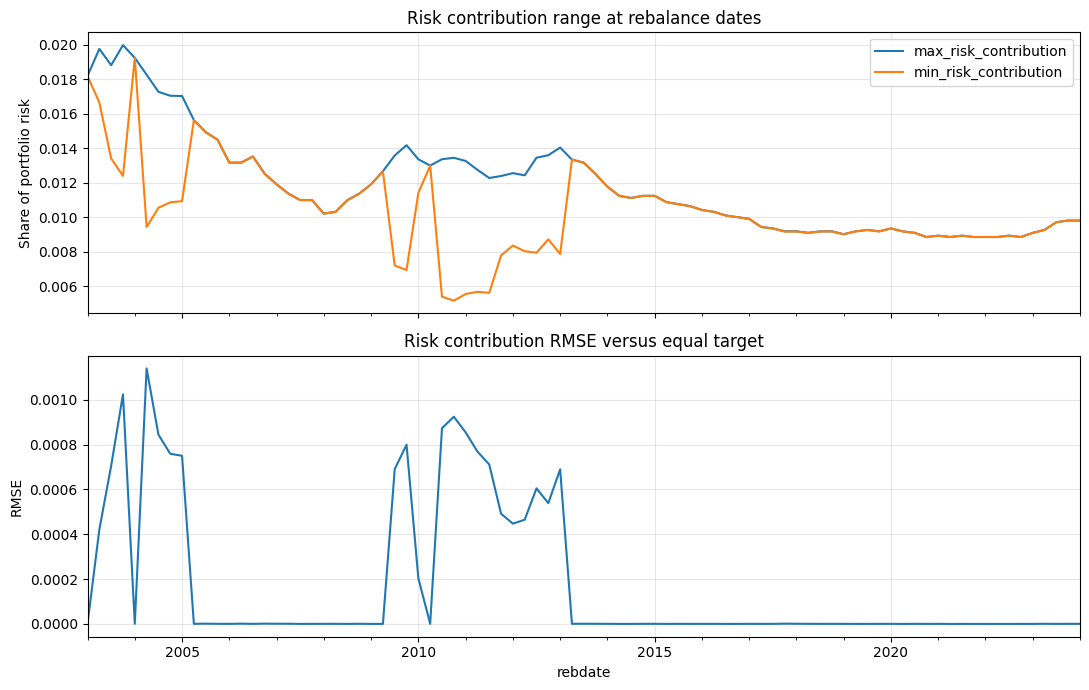

,count,mean,std,min,25%,50%,75%,max
holdings,85.0,89.000000,18.159348,5.100000e+01,7.600000e+01,8.900000e+01,108.000000,113.000000
max_capital_weight,85.0,0.066419,0.024878,2.659581e-02,4.809966e-02,5.909163e-02,0.099601,0.100000
max_risk_contribution,85.0,0.011862,0.002890,8.850234e-03,9.264847e-03,1.123674e-02,0.013336,0.019970
min_risk_contribution,85.0,0.010365,0.002565,5.162549e-03,8.927466e-03,9.899596e-03,0.011357,0.019228
risk_contribution_rmse,85.0,0.000173,0.000322,2.054387e-07,4.734366e-07,6.472753e-07,0.000002,0.001139


In [17]:

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
rc_diag[['max_risk_contribution', 'min_risk_contribution']].plot(
    ax=axes[0],
    title='Risk contribution range at rebalance dates',
)
axes[0].set_ylabel('Share of portfolio risk')
axes[0].grid(alpha=0.3)
rc_diag['risk_contribution_rmse'].plot(ax=axes[1], title='Risk contribution RMSE versus equal target')
axes[1].set_ylabel('RMSE')
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

rc_diag.describe().T


## 10. Selection Diagnostics

In [18]:

selection_counts = []
for rebdate in rebdates:
    bs_s23.build_selection(rebdate)
    binary = bs_s23.selection.df_binary()
    counts = binary.sum(axis=0).rename(rebdate)
    counts['selected_after_all_filters'] = binary.eq(1).all(axis=1).sum()
    selection_counts.append(counts)

selection_counts = pd.DataFrame(selection_counts)
selection_counts.index = pd.to_datetime(selection_counts.index)
selection_counts.tail()


,return_history,gaps,min_volume,selected_after_all_filters
2023-01-31,181,174,113,110
2023-04-30,182,174,110,108
2023-07-31,180,171,104,103
2023-10-31,177,172,103,102
2024-01-31,177,172,103,102


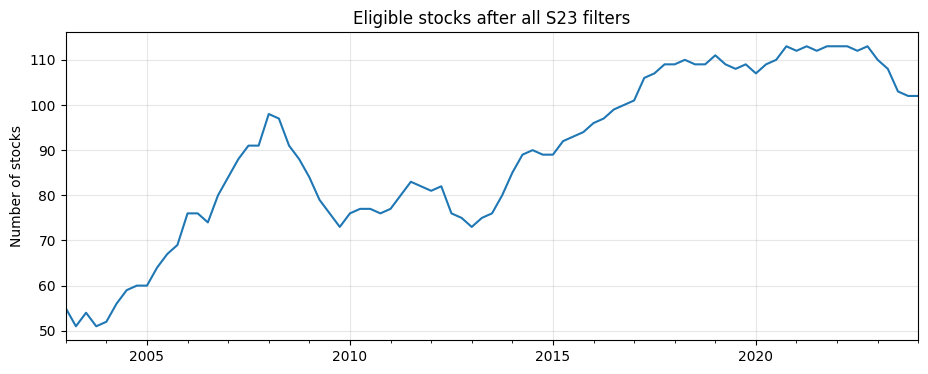

,count,mean,std,min,25%,50%,75%,max
return_history,85.0,171.388235,15.394877,127.0,170.0,178.0,180.0,186.0
gaps,85.0,179.282353,5.319801,171.0,175.0,179.0,183.0,190.0
min_volume,85.0,90.729412,18.591081,53.0,78.0,91.0,110.0,116.0
selected_after_all_filters,85.0,89.000000,18.159348,51.0,76.0,89.0,108.0,113.0


In [19]:

ax = selection_counts['selected_after_all_filters'].plot(
    figsize=(11, 4),
    title='Eligible stocks after all Strategy filters',
)
ax.set_ylabel('Number of stocks')
ax.grid(alpha=0.3)
plt.show()

selection_counts.describe().T


## 11. Summary

The strategy is a risk-based Swiss equity strategy. It does not forecast expected returns; instead, it builds a liquid universe, estimates a trailing shrinkage covariance matrix, and solves for weights with approximately equal risk contribution subject to long-only and stock-cap constraints. This follows the risk-parity/equal-risk-contribution idea associated with Maillard, Roncalli, and Teiletche, and is useful as a robust core sleeve because it avoids relying on noisy return forecasts.

The main implementation risk is that equal-risk-contribution portfolios can still concentrate in low-volatility or highly correlated defensive names. The 10% stock cap, quarterly rebalancing, liquidity screen, and risk-contribution diagnostics are included to keep that risk visible.